# Four ways to travel in Europe
**Part I of II:** grouping 235 European cities into travel styles with K-means and Archetypal Analysis (AA). [Part II](02_next_trip_recommender.ipynb) recommends a traveller's next destination.

**Audience:**  a travel website where users choose their next destination based on budget, safety, internet, nightlife and leisure. The site wants a **"Browse by travel style"** page and a *"You might also like"* recommendation.

**Why K-means :**
- **One city, one category.** K-means gives each city exactly one label. AA gives mixes, which are harder to understand for the consumer.
- **Realistic profiles.** A K-means centroid is the *typical* city of a group. An AA archetype is an *extreme* city that few real destinations match.


We try both methods and compare them with the Adjusted Rand Index (ARI).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from archetypes import AA


PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]
MARKERS = ["o", "s", "^", "D"]
MIXED_GREY = "#9a9994"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

Using NumPy backend


## 1. We load and clean the data

In [2]:
cities = pd.read_csv("https://sds-aau.github.io/SDS-master/M1/data/cities.csv")
print(cities.shape)
cities.head()

(780, 25)


,place,alpha-2,region,sub-region,cost_nomad,cost_coworking,cost_expat,coffee_in_cafe,cost_beer,places_to_work,...,fragile_states_index,press_freedom_index,female_friendly,lgbt_friendly,friendly_to_foreigners,racism,leisure,life_score,nightlife,weed
0,Budapest,HU,Europe,Eastern Europe,1364.0,152.41,1273.0,1.73,1.73,1.0,...,52.7,28.17,1.0,0.27,0.6,0.40,0.80,0.86,1.00,0.0
1,Chiang Mai,TH,Asia,South-eastern Asia,777.0,98.88,780.0,0.85,0.85,0.8,...,78.8,44.53,0.8,0.60,0.6,0.40,0.62,0.75,0.40,0.0
2,Phuket,TH,Asia,South-eastern Asia,1012.0,155.43,1714.0,1.41,1.41,0.8,...,78.8,44.53,0.6,0.80,0.6,0.42,0.60,0.75,0.82,0.0
3,Bangkok,TH,Asia,South-eastern Asia,1197.0,131.41,1158.0,2.12,2.12,1.0,...,78.8,44.53,0.8,0.80,1.0,0.42,0.82,0.72,1.00,0.0
4,Ko Samui,TH,Asia,South-eastern Asia,1352.0,169.56,1347.0,1.41,1.41,0.8,...,78.8,44.53,0.8,0.80,1.0,0.40,0.80,0.80,0.80,0.0


Three data problems we found, we will fix before clustering 

1. `internet_speed = 0` for 107 cities (e.g. Montreal, Malmö, Malaga). 0 Mbps is not real – it means missing.
2. `coffee_in_cafe = 0` for 18 cities – also missing.
3. `cost_beer` is an exact copy of `coffee_in_cafe`, and `racism` has one absurd value (Samara ≈ 1.8e28). We don't use these two columns

In [3]:
print("internet_speed == 0:", (cities["internet_speed"] == 0).sum())
print("coffee_in_cafe == 0:", (cities["coffee_in_cafe"] == 0).sum())
print("cost_beer identical to coffee_in_cafe:", (cities["cost_beer"] == cities["coffee_in_cafe"]).all())
print("max racism value:", cities["racism"].max())

internet_speed == 0: 107
coffee_in_cafe == 0: 18
cost_beer identical to coffee_in_cafe: True
max racism value: 1.8181818181818e+28


In [4]:
# Treat 0 as missing and complete with the median of the same country,
# take to the median of the sub-region if the whole country is missing

for col in ["internet_speed", "coffee_in_cafe"]:
    cities[col] = cities[col].replace(0, np.nan)
    cities[col] = (cities[col]
                   .fillna(cities.groupby("alpha-2")[col].transform("median"))
                   .fillna(cities.groupby("sub-region")[col].transform("median")))
    print(col, "missing after imputation:", cities[col].isna().sum())

internet_speed missing after imputation: 0
coffee_in_cafe missing after imputation: 0


In [5]:
# Keep only European cities (after cleaning)
cities = cities[cities["region"] == "Europe"].reset_index(drop=True)
print(cities.shape)
cities["sub-region"].value_counts()

(235, 25)


sub-region
Southern Europe    70
Western Europe     58
Northern Europe    54
Eastern Europe     53
Name: count, dtype: int64

## 2. We chose the features our audience cares about

A traveller choosing a destination asks a few questions. Many travellers today also work remotely
while travelling.

| Question | Features |
|---|---|
| Can I afford it? | `cost_nomad`, `cost_coworking`, `coffee_in_cafe` |
| Can I stay connected / work there? | `internet_speed`, `places_to_work`, `free_wifi_available` |
| Will I feel safe and welcome? | `safety`, `female_friendly`, `lgbt_friendly`, `friendly_to_foreigners` |
| Will I enjoy my free time? | `nightlife`, `leisure` |

Money and internet speed are strongly right-skewed (a few very expensive / very fast cities), so we **log-transform** them
and then **standardise** everything, so every feature has the same weight.



In [6]:
features = ["cost_nomad", "cost_coworking", "coffee_in_cafe",
            "internet_speed", "places_to_work", "free_wifi_available",
            "safety", "female_friendly", "lgbt_friendly", "friendly_to_foreigners",
            "nightlife", "leisure"]
log_features = ["cost_nomad", "cost_coworking", "coffee_in_cafe", "internet_speed"]

X_df = cities[features].copy()
X_df[log_features] = np.log(X_df[log_features])

scaler = StandardScaler()
X = scaler.fit_transform(X_df)     # 235 cities x 12 features, z-scores
X.shape

(235, 12)

235 cities and 12 variables ready for CLUSTERING

In [7]:
def to_original_units(Z):
    """Convert z-scores back to the original units ."""
    out = pd.DataFrame(scaler.inverse_transform(Z), columns=features)
    out[log_features] = np.exp(out[log_features])
    return out

    # We convert results back to real units (USD, Mbps) so they are easy to interpret

# 3. **How Many Groups??**

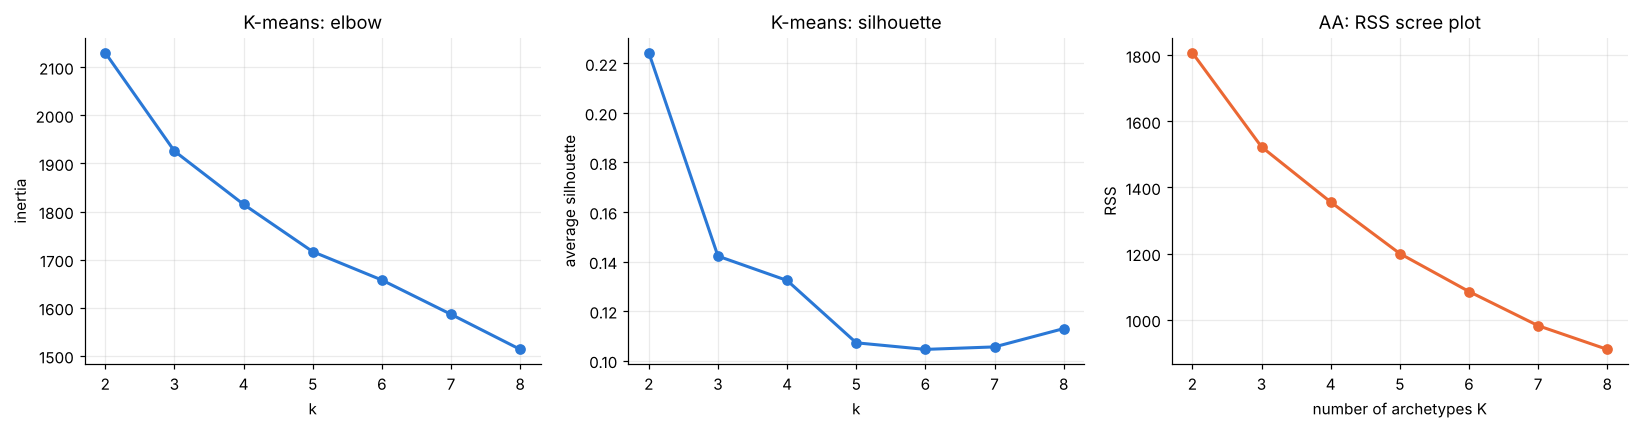

In [8]:
ks = range(2, 9)
inertia, silhouette, rss = [], [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

    best_rss = min(AA(n_archetypes=k, max_iter=1000, random_state=seed).fit(X).rss_ for seed in range(10))
    rss.append(best_rss)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ks, inertia, marker="o", color=PALETTE[0], lw=2)
axes[0].set(title="K-means: elbow", xlabel="k", ylabel="inertia")
axes[1].plot(ks, silhouette, marker="o", color=PALETTE[0], lw=2)
axes[1].set(title="K-means: silhouette", xlabel="k", ylabel="average silhouette")
axes[2].plot(ks, rss, marker="o", color=PALETTE[1], lw=2)
axes[2].set(title="AA: RSS scree plot", xlabel="number of archetypes K", ylabel="RSS")
plt.tight_layout()
plt.show()

**Choice of k:** The silhouette is highest at k = 2, two groups are too small for a travel website. From k = 3 to k = 4 the silhouette barely changes (0.14 → 0.13), and after k = 4 it drops clearly (0.11). So we choose **k = 4**, which gives four clear travel styles without losing separation. We use the same k for AA so that the two methods can be compared fairly with ARI.

In [9]:
K = 4

## 4. K-means with k = 4

In [10]:
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
cities["km_cluster"] = kmeans.labels_

km_centroids = to_original_units(kmeans.cluster_centers_)
km_centroids.index = [f"C{i}" for i in range(K)]
km_centroids.round(2).T

,C0,C1,C2,C3
cost_nomad,2976.06,2998.45,1728.03,1034.17
cost_coworking,225.29,291.70,124.61,72.71
coffee_in_cafe,4.73,4.65,1.98,1.56
internet_speed,19.22,14.70,16.36,10.87
places_to_work,0.70,0.53,0.57,0.49
free_wifi_available,0.66,0.61,0.60,0.40
safety,0.89,0.79,0.69,0.46
female_friendly,0.90,0.67,0.65,0.34
lgbt_friendly,0.82,0.54,0.42,0.23
friendly_to_foreigners,0.86,0.69,0.76,0.65


In [11]:
# K-means numbers  - give names based on their centroid (z-scores)
cz = pd.DataFrame(kmeans.cluster_centers_, columns=features)
overall = cz.mean(axis=1)                                          # overall level of each cluster
cost = cz[["cost_nomad", "cost_coworking", "coffee_in_cafe"]].mean(axis=1)

km_names = {}
km_names[overall.idxmax()] = "Premium & Safe"
km_names[overall.idxmin()] = "Budget & basic"
rest = [c for c in range(K) if c not in km_names]
km_names[cost[rest].idxmin()] = "Affordable & balanced"
km_names[cost[rest].idxmax()] = "Pricey & quiet"

cities["km_type"] = cities["km_cluster"].map(km_names)
km_centroids.index = [km_names[c] for c in range(K)]
print(km_names)

{0: 'Premium & Safe', 3: 'Budget & basic', 2: 'Affordable & balanced', 1: 'Pricey & quiet'}


**The last two lines put the cluster names in the centroid table (instead of C0–C3) and print which cluster number got which name.**

In [12]:
# The most TYPICAL cities of each group = the cities closest to the centroid
dist_to_centroid = kmeans.transform(X)          # distance of every city to every centroid
cities["dist_to_own_centroid"] = dist_to_centroid[np.arange(len(cities)), kmeans.labels_]

for c in range(K):
    members = cities[cities["km_cluster"] == c].sort_values("dist_to_own_centroid")
    print(f"{km_names[c]:<24} n={len(members):>3}  most typical: {', '.join(members['place'].head(8))}")

Premium & Safe           n= 99  most typical: Sliema, Stuttgart, Leiden, Espoo, Tilburg, Southampton, Liverpool, Utrecht
Pricey & quiet           n= 60  most typical: Erlangen, Rimini, Lucca, Cagliari, Cheltenham, A Coruna, Luxembourg, Monza
Affordable & balanced    n= 58  most typical: Como, Funchal, Craiova, Brasov, Zagreb, Tirana, Bratislava, Iasi
Budget & basic           n= 18  most typical: Saratov, Ivano-Frankivsk, Samara, Kharkiv, Novosibirsk, Krivoy-Rog, Ufa, Izhevsk


**EXAMPLE**

In [13]:
known = ["Copenhagen", "Aalborg", "Berlin", "London", "Paris", "Lisbon", "Barcelona", "Prague", "Budapest", "Bucharest"]
cities.set_index("place").loc[known, "km_type"]

place
Copenhagen           Premium & Safe
Aalborg              Premium & Safe
Berlin               Premium & Safe
London               Premium & Safe
Paris                Premium & Safe
Lisbon               Premium & Safe
Barcelona            Premium & Safe
Prague               Premium & Safe
Budapest      Affordable & balanced
Bucharest     Affordable & balanced
Name: km_type, dtype: str

## 5. Archetypal Analysis with K = 4 (for comparison)

Run AA 20 times with different random starts and keep the best solution.

In [14]:

aa_runs = [AA(n_archetypes=K, max_iter=1000, random_state=seed).fit(X) for seed in range(20)]
aa = min(aa_runs, key=lambda m: m.rss_)
print("RSS of best run:", round(aa.rss_, 1))
print("RSS range over seeds:", round(min(m.rss_ for m in aa_runs), 1), "-", round(max(m.rss_ for m in aa_runs), 1))

archetypes_orig = to_original_units(aa.archetypes_)   # archetypes in real units
alpha = aa.coefficients_                              # 235 x 4: each city's mix of archetypes
archetypes_orig.index = [f"A{i}" for i in range(K)]
archetypes_orig.round(2).T

RSS of best run: 1356.1
RSS range over seeds: 1356.1 - 1382.6


,A0,A1,A2,A3
cost_nomad,1990.75,5847.13,2411.02,885.05
cost_coworking,166.84,1222.85,112.48,54.09
coffee_in_cafe,3.91,9.65,3.48,1.02
internet_speed,16.60,20.83,19.09,11.42
places_to_work,0.97,0.46,0.78,0.30
free_wifi_available,0.88,0.49,0.82,0.31
safety,0.57,1.00,0.97,0.40
female_friendly,0.43,0.83,1.00,0.32
lgbt_friendly,0.20,0.80,0.92,0.20
friendly_to_foreigners,0.52,0.79,1.00,0.59


**Creating The Names of the Archetypes**

In [15]:
# AA numbers its archetypes - name them from their profile (z-scores)
az = pd.DataFrame(aa.archetypes_, columns=features)
cost = az[["cost_nomad", "cost_coworking", "coffee_in_cafe"]].mean(axis=1)

aa_names = {}
aa_names[cost.idxmin()] = "Budget & basic"
aa_names[cost.idxmax()] = "Luxury & exclusive"
rest = [a for a in range(K) if a not in aa_names]
aa_names[az.loc[rest, "friendly_to_foreigners"].idxmax()] = "Open & lively"
rest = [a for a in range(K) if a not in aa_names]
aa_names[rest[0]] = "Lively but less welcoming"
assert len(set(aa_names.values())) == K, "naming rule failed - check the archetype table"

archetypes_orig.index = [aa_names[a] for a in range(K)]
print(aa_names)
archetypes_orig.round(2).T

{3: 'Budget & basic', 1: 'Luxury & exclusive', 2: 'Open & lively', 0: 'Lively but less welcoming'}


,Lively but less welcoming,Luxury & exclusive,Open & lively,Budget & basic
cost_nomad,1990.75,5847.13,2411.02,885.05
cost_coworking,166.84,1222.85,112.48,54.09
coffee_in_cafe,3.91,9.65,3.48,1.02
internet_speed,16.60,20.83,19.09,11.42
places_to_work,0.97,0.46,0.78,0.30
free_wifi_available,0.88,0.49,0.82,0.31
safety,0.57,1.00,0.97,0.40
female_friendly,0.43,0.83,1.00,0.32
lgbt_friendly,0.20,0.80,0.92,0.20
friendly_to_foreigners,0.52,0.79,1.00,0.59


**EXAMPLE**

In [16]:
# The cities closest to each "pure" archetype (highest alpha)
for a in range(K):
    top = cities["place"].iloc[np.argsort(-alpha[:, a])[:8]]
    print(f"{aa_names[a]:<26} {', '.join(top)}")

Lively but less welcoming  Moscow, Kiev, Warsaw, Milan, Sofia, Brussels, Pisa, Budapest
Luxury & exclusive         Lausanne, Aalesund, Venice, Geneva, Saint Helier, Deventer, Luxembourg, Naples
Open & lively              Berlin, Bern, Glasgow, Newcastle Upon Tyne, Tallinn, Helsinki, Gdansk, Leiden
Budget & basic             Obninsk, Hama, Krivoy-Rog, Grodno, Samara, Kharkiv, Rostov-on-Don, Lviv


**LAST STEP**

In [17]:
# Dominant archetype (largest alpha) + how "pure" each city is
cities["aa_archetype"] = alpha.argmax(axis=1)
cities["aa_strength"] = alpha.max(axis=1)
cities["aa_type"] = cities["aa_archetype"].map(aa_names)

print(cities["aa_type"].value_counts())
print("\nCities that are >= 70 % one archetype:", (cities["aa_strength"] >= 0.7).sum(), "of", len(cities))
print("Cities that are < 50 % one archetype (mixed):", (cities["aa_strength"] < 0.5).sum(), "of", len(cities))

aa_type
Open & lively                91
Luxury & exclusive           67
Budget & basic               56
Lively but less welcoming    21
Name: count, dtype: int64

Cities that are >= 70 % one archetype: 36 of 235
Cities that are < 50 % one archetype (mixed): 96 of 235


**Interpretation:** 
AA found four extreme city profiles in Europe: *Open & lively hub* (e.g. Berlin, Helsinki), *Luxury & exclusive* (e.g. Geneva, Venice), *Budget & basic* (e.g. Kharkiv, Lviv) and *Lively but less welcoming* (e.g. Moscow, Warsaw). However, only 36 of 235 cities (~15 %) are at least 70 % one archetype, and 96 cities (~40 %) are mixes where no archetype reaches 50 %.  

The remaining 103 cities (~44 %) are **mainly a mix!**

**For the website this makes AA less suitable as the main method: a "Browse by travel style" page needs each city in one clear category, but most European cities are blends of several archetypes. AA is still useful as a complement, because it highlights the extreme profiles (e.g. the luxury segment) that the K-means averages hide.**

# 6. Visualization

**Heatmaps with the K-means and AA one next to each other.**

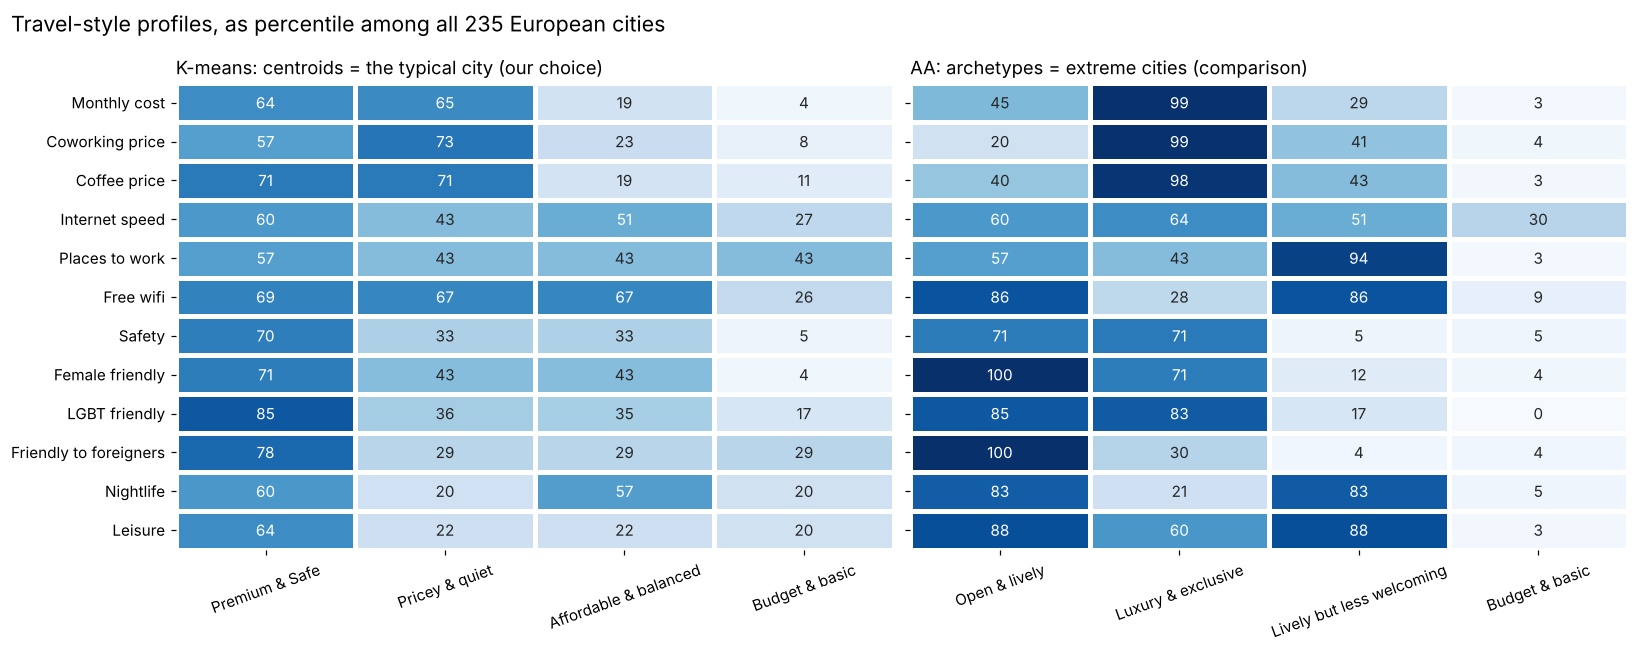

In [18]:
pretty = {"cost_nomad": "Monthly cost", "cost_coworking": "Coworking price", "coffee_in_cafe": "Coffee price",
          "internet_speed": "Internet speed", "places_to_work": "Places to work", "free_wifi_available": "Free wifi",
          "safety": "Safety", "female_friendly": "Female friendly", "lgbt_friendly": "LGBT friendly",
          "friendly_to_foreigners": "Friendly to foreigners", "nightlife": "Nightlife", "leisure": "Leisure"}

def percentile_profile(profile_df):
    """Percentile of each profile value within the distribution of all cities."""
    return pd.DataFrame({f: [(cities[f] <= v).mean() * 100 for v in profile_df[f]] for f in features},
                        index=profile_df.index)

# Order the groups so that similar K-means / AA types sit in the same position
km_order = ["Premium & Safe", "Pricey & quiet", "Affordable & balanced", "Budget & basic"]
aa_order = ["Open & lively", "Luxury & exclusive", "Lively but less welcoming", "Budget & basic"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, prof, order, title in [(axes[0], km_centroids, km_order, "K-means: centroids = the typical city (our choice)"),
                               (axes[1], archetypes_orig, aa_order, "AA: archetypes = extreme cities (comparison)")]:
    p = percentile_profile(prof.loc[order]).rename(columns=pretty).T
    sns.heatmap(p, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                linewidths=2, linecolor="white", ax=ax)
    ax.grid(False)
    ax.set_title(title, loc="left", fontsize=12)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("")
fig.suptitle(f"Travel-style profiles, as percentile among all {len(cities)} European cities", x=0.01, ha="left", fontsize=14)
plt.tight_layout()
plt.show()

**INTERPRET.:** each cell shows where a group stands compared with 235 European cities **(100 = highest). **

**K-means** gives realistic expectations: *Premium & Safe* cities are the most open and welcoming but expensive; *Pricey & quiet* cities cost almost as much but score low on safety, nightlife and leisure (the worst value for money); *Affordable & balanced* cities are cheap with decent wifi and nightlife; *Budget & basic* cities are the cheapest but the least safe. 


**AA** shows much **more extreme values** (many 0s and 100s), because archetypes are the "purest" cities at the edge of the data. They are useful to understand the extremes (e.g. the luxury segment), but few real cities look like them.

# 7. PCA

**PCA transforms the 12 Dimensions into 2 dimensions so we can create the Graphics. ( A Graphic has 2 dimensions)**

Variance explained by PC1 + PC2: 0.49


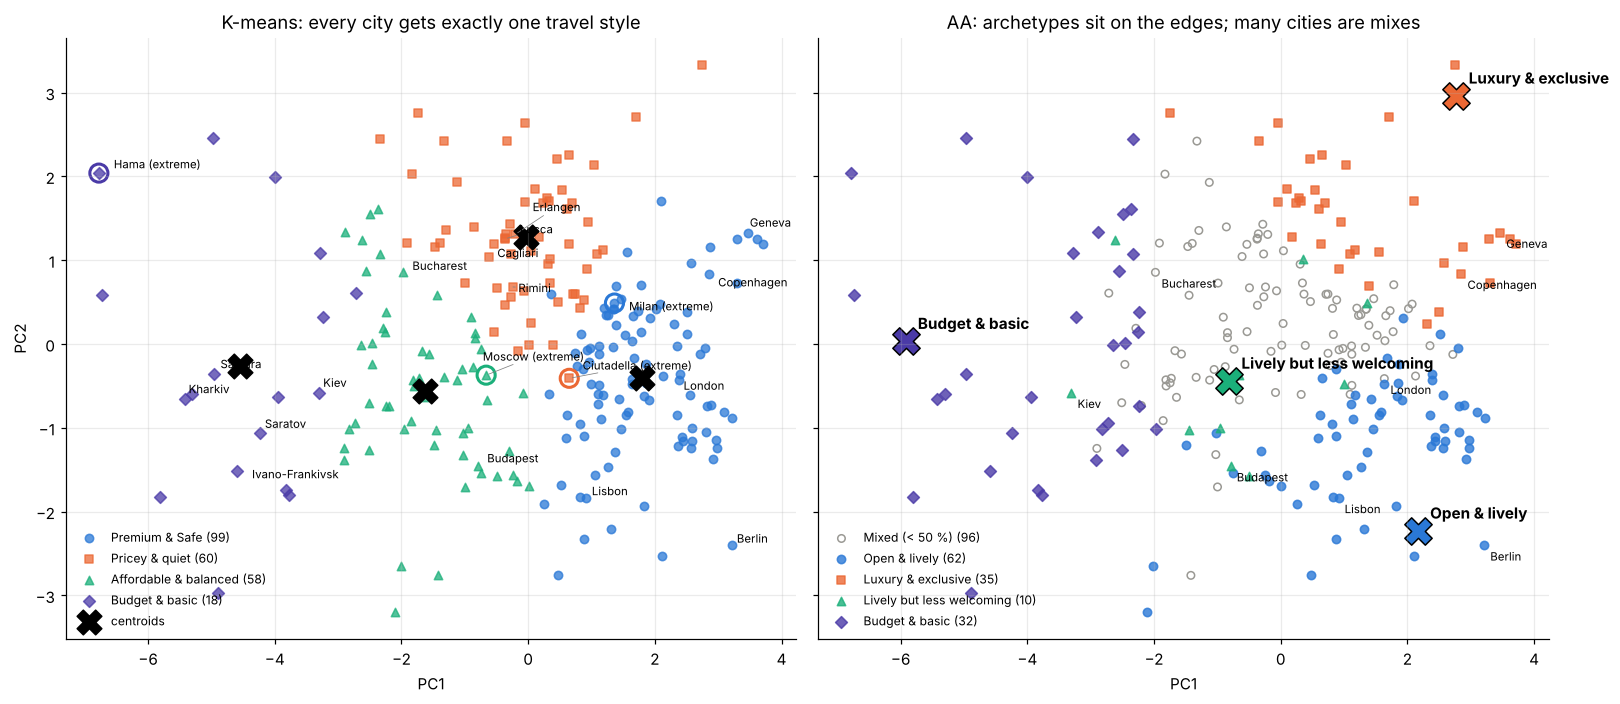

In [19]:
from adjustText import adjust_text

pca = PCA(n_components=2).fit(X)
P, P_arch = pca.transform(X), pca.transform(aa.archetypes_)
print("Variance explained by PC1 + PC2:", pca.explained_variance_ratio_.sum().round(2))

def row(city):
    """Row number of a city in the table."""
    return cities.index[cities["place"] == city][0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)

# Left: K-means groups + centroids
for i, name in enumerate(km_order):
    m = cities["km_type"] == name
    ax1.scatter(P[m, 0], P[m, 1], s=30, alpha=0.75, color=PALETTE[i], marker=MARKERS[i], label=f"{name} ({m.sum()})")
C = pca.transform(kmeans.cluster_centers_)
ax1.scatter(C[:, 0], C[:, 1], marker="X", s=260, c="black", label="centroids")

# Right: AA types (mixed cities in grey) + archetypes
mixed = cities["aa_strength"] < 0.5
ax2.scatter(P[mixed, 0], P[mixed, 1], s=24, facecolors="none", edgecolors=MIXED_GREY, label=f"Mixed (< 50 %) ({mixed.sum()})")
for i, name in enumerate(aa_order):
    m = (cities["aa_type"] == name) & ~mixed
    a = [k for k, v in aa_names.items() if v == name][0]
    ax2.scatter(P[m, 0], P[m, 1], s=30, alpha=0.8, color=PALETTE[i], marker=MARKERS[i], label=f"{name} ({m.sum()})")
    ax2.scatter(*P_arch[a], marker="X", s=320, color=PALETTE[i], edgecolor="black")
    ax2.annotate(name, P_arch[a], xytext=(8, 8), textcoords="offset points", weight="bold")

# Labels: famous cities + 4 typical cities (orange, purple) + the extreme city of each group
famous = ["Copenhagen", "Berlin", "London", "Lisbon", "Budapest", "Bucharest", "Geneva", "Kiev"]
labels = {row(c): c for c in famous}
for name in ["Pricey & quiet", "Budget & basic"]:
    for i in cities[cities["km_type"] == name].nsmallest(4, "dist_to_own_centroid").index:
        labels[i] = cities.loc[i, "place"]
for g, name in enumerate(km_order):
    j = cities[cities["km_type"] == name]["dist_to_own_centroid"].idxmax()
    ax1.scatter(*P[j], s=140, facecolors="none", edgecolors=PALETTE[g], linewidth=2)
    labels[j] = cities.loc[j, "place"] + " (extreme)"

texts = [ax1.text(*P[i], t, fontsize=7.5) for i, t in labels.items()]
adjust_text(texts, ax=ax1, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
for c in famous:
    ax2.annotate(c, P[row(c)], xytext=(4, -10), textcoords="offset points", fontsize=7.5)

ax1.set(title="K-means: every city gets exactly one travel style", xlabel="PC1", ylabel="PC2")
ax2.set(title="AA: archetypes sit on the edges; many cities are mixes", xlabel="PC1")
for ax in (ax1, ax2):
    ax.legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Map of all European cities (PCA).** PCA compresses the 12 features into 2 dimensions only to *draw* the cities ; both methods were fitted on all 12 features.
- **Left (K-means):** every city gets exactly one colour. Black X = centroid (the typical city). Circled cities are the most extreme member of each group, e.g. Hama, which is in fact a Syrian city mislabelled as European in the dataset.
- **Right (AA):** the archetypes (coloured X) sit on the edges of the cloud, and 96 cities (grey circles) are mixes that do not clearly belong to any archetype.

This confirms our choice: K-means gives clear, non-overlapping categories for the website, while AA mainly describes the extremes.

# 8. "You might also like"
For a city page, the website can recommend the **nearest cities from the same K-means travel style**
(distance on all 12 standardised features).

In [20]:
def similar_cities(city, n=5):
    """The n cities closest to `city` that belong to the same K-means travel style."""
    i = cities.index[cities["place"] == city][0]
    same = cities.index[(cities["km_cluster"] == cities.loc[i, "km_cluster"]) & (cities.index != i)]
    d = np.linalg.norm(X[same] - X[i], axis=1)
    return cities.loc[same[np.argsort(d)[:n]], "place"].tolist()

for city in ["Copenhagen", "Aalborg", "Lisbon", "Budapest", "Bucharest"]:
    style = cities.loc[cities["place"] == city, "km_type"].iloc[0]
    print(f"{city:<11} [{style}] -> you might also like: {', '.join(similar_cities(city))}")

Copenhagen  [Premium & Safe] -> you might also like: Aalesund, Dublin, Stockholm, Hamburg, Edinburgh
Aalborg     [Premium & Safe] -> you might also like: Aarhus, Bergen, Reykjavik, Tilburg, Zurich
Lisbon      [Premium & Safe] -> you might also like: Las Palmas, Palma De Mallorca, Gothenburg, Prague, Berlin
Budapest    [Affordable & balanced] -> you might also like: Belgrade, Kaunas, Porto, Bratislava, Cluj
Bucharest   [Affordable & balanced] -> you might also like: Iasi, Kaunas, Timisoara, Craiova, Brasov


The suggestions make sense without the model knowing any geography: Aalborg gets Aarhus and Bergen, and Bucharest gets other Romanian cities (Iasi, Timisoara, Craiova, Brasov). The trade-off is that the list always stays within the same travel style, so a traveller looking for a *cheaper* alternative to Copenhagen would need a different rule.

# 9. ARI 

**Why?** K-means and AA give their groups different names and numbers, so we cannot compare the labels directly. The Adjusted Rand Index (ARI) solves this: it looks at every **pair of cities** and checks whether both methods put them in the *same* group or in *different* groups. 


Adjusted Rand Index (K-means vs AA): 0.354


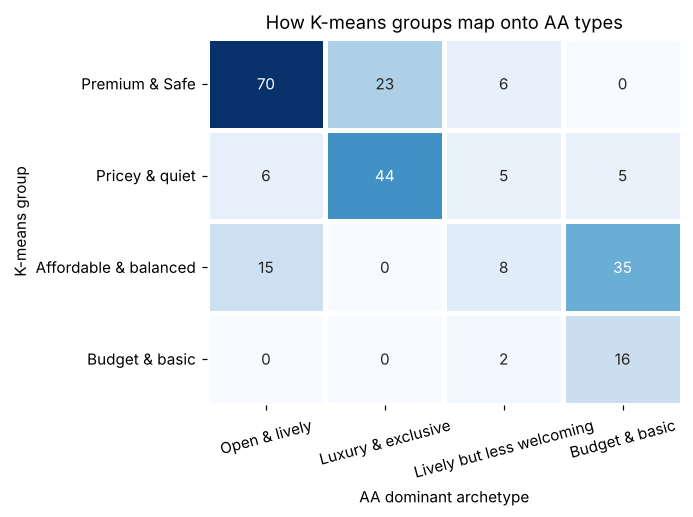

In [21]:
ari = adjusted_rand_score(cities["km_cluster"], cities["aa_archetype"])
print("Adjusted Rand Index (K-means vs AA):", round(ari, 3))

# How do the K-means groups map onto the AA types?
ct = pd.crosstab(cities["km_type"], cities["aa_type"]).loc[km_order, aa_order]
ax = sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white")
ax.grid(False)
ax.set(title="How K-means groups map onto AA types", xlabel="AA dominant archetype", ylabel="K-means group")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**ARI = 0.35:** ARI = 1 means identical groupings, ARI ≈ 0 means no more agreement than chance. Our value of **0.35** indicates **partial agreement**:

The two methods agree only partly. They match well on the extremes: *Premium & Safe* mostly becomes *Open & lively* (70/99), *Pricey & quiet* mostly becomes *Luxury & exclusive* (44/60), and *Budget & basic* is almost identical in both (16/18). The main difference is the middle: K-means' *Affordable & balanced* group has no archetype of its own, and AA splits it between *Budget & basic*, *Open & lively* and *Lively but less welcoming*.

**Decision: we keep K-means.** 
The difference is substantial, but it confirms our choice rather than contradicting it. The popular, affordable middle of Europe (e.g. Budapest, Bucharest, Zagreb) is exactly a category travellers want to browse, and only K-means gives it. AA adds useful insight on the edges, e.g. a separate *Luxury* segment, which the Site could use as an extra filter, but not as the main menu.

# 10. Final

## The story: four ways to travel in Europe

We looked at 235 European cities and asked a simple question: *what kinds of cities are there for a traveller?* The data points to four travel styles:

- **Premium & Safe** (e.g. Copenhagen, Berlin, London, Lisbon): safe, open-minded and full of things to do. You pay for it (about $3,000 a month), but you get the most complete experience.
- **Pricey & quiet** (e.g. Rimini, Luxembourg): almost as expensive, but with less nightlife and fewer activities. These are the cities where travellers get the **least for their money** in our opinion.
- **Affordable & balanced** (e.g. Budapest, Bucharest, Zagreb, Bratislava): about 40 % cheaper (around $1,700 a month), with good wifi and a decent nightlife. This is the **best-value option**.
- **Budget & basic** (e.g. Kiev, Kharkiv, Samara): the cheapest (around $1,000 a month), but also the least safe and least welcoming. Best for experienced, adventurous travellers.

**What it means ? :** these four styles are the four tabs of the "Browse by travel style" page. 